In [2]:
from typing_extensions import List , Literal
from pydantic  import BaseModel, Field
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode , tools_condition
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
import faiss


load_dotenv()
llm = ChatGroq(model="openai/gpt-oss-120b",temperature=0.5)

In [3]:
llm.invoke("hi")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "hi". Simple greeting. Should respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.083550784, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.016879953, 'prompt_tokens_details': None, 'queue_time': 0.374738576, 'total_time': 0.100430737}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_27194a498a', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0ec4e-90fe-7d93-a752-17c732c1ab88-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_token_details': {'reasoning': 22}})

In [4]:
from typing import Annotated 
from langgraph.graph.message import add_messages
from langchain_core.messages import AnyMessage

In [5]:
class State(BaseModel):
    messages: Annotated[list[AnyMessage], add_messages] = Field(default_factory=list)
    response: str = ""

In [6]:
import sqlite3
DB_PATH = "clinic.db"
conn = sqlite3.connect(DB_PATH, check_same_thread=False)
conn.execute("PRAGMA foreign_keys = ON")
cur = conn.cursor()

In [7]:
import re

PHONE_PATTERN = re.compile(r"^(?:0020|20|\+20)?0?1[0-25]\d{8}$")

def is_valid_phone(phone: str) -> bool:
    return bool(PHONE_PATTERN.match(re.sub(r"[\s\-]", "", phone)))

print(is_valid_phone("201017989362"))

True


In [8]:
def normalize_phone(phone: str) -> str:
    """Convert any phone format into the DB's stored format: 0XXXXXXXXXX."""
    digits = re.sub(r"\D", "", phone)  # strip spaces, dashes, +, etc.

    if digits.startswith("0020"):
        digits = digits[2:]           # 0020... -> 20...
    if digits.startswith("20") and len(digits) == 12:
        digits = "0" + digits[2:]     # 20XXXXXXXXXX -> 0XXXXXXXXXX

    return digits

In [9]:
from langchain_core.tools import tool

@tool
def search_patient(name: str | None = None, phone: str | None = None) -> str:
    """Use this tool to look up a patient by phone number or name. Prefer the phone number over the name when both are given."""

    if phone and is_valid_phone(phone):
        normalized = normalize_phone(phone)
        cur.execute("SELECT id, name FROM patients WHERE phone = ?", (normalized,))
        row = cur.fetchone()
        if row:
            patient_id, patient_name = row
            return f"id={patient_id}, name={patient_name}"
        return f"No patient found with phone '{phone}'."

    if name:
        cur.execute("SELECT id, name, phone FROM patients WHERE name LIKE ?", (f"%{name}%",))
        rows = cur.fetchall()
        if rows:
            return "\n".join(f"id={r[0]}, name={r[1]}, phone={r[2]}" for r in rows)
        return f"No patient found with name '{name}'."

    return "Please provide a patient name or phone number to search."

@tool
def get_patient_history(name: str | None = None, phone: str | None = None) -> str:
    """Use this tool to look up a patient's history of past appointments by phone number or name. Prefer the phone number over the name when both are given."""

    if phone and is_valid_phone(phone):
        normalized = normalize_phone(phone)
        cur.execute("SELECT id, name FROM patients WHERE phone = ?", (normalized,))
        row = cur.fetchone()

        if row:
            patient_id, patient_name = row
            cur.execute(
                """SELECT s.date, s.time, d.name, a.status, a.reason
                   FROM appointments a
                   JOIN slots s ON a.slot_id = s.id
                   JOIN doctors d ON a.doctor_id = d.id
                   WHERE a.patient_id = ?
                   ORDER BY s.date, s.time""",
                (patient_id,)
            )
            appointments = cur.fetchall()

            if not appointments:
                return f"{patient_name} (id={patient_id}) has no appointment history."

            lines = [f"{date} {time} with {doctor} - {status} ({reason})"
                     for date, time, doctor, status, reason in appointments]
            return f"History for {patient_name} (id={patient_id}):\n" + "\n".join(lines)

        return f"No patient found with phone '{phone}'."

    if name:
        cur.execute("SELECT id, name, phone FROM patients WHERE name LIKE ?", (f"%{name}%",))
        rows = cur.fetchall()
        if rows:
            return "\n".join(f"id={r[0]}, name={r[1]}, phone={r[2]}" for r in rows)
        return f"No patient found with name '{name}'."

    return "Please provide a patient name or phone number."

In [10]:
@tool
def list_doctors(speciality: str | None = None) -> str:
    """Use this tool to look up the clinic's doctors. Optionally filter by speciality (e.g. 'dentist', 'cardiology'); leave it empty to list all doctors."""

    if speciality:
        cur.execute("SELECT id, name, specialty FROM doctors WHERE specialty LIKE ?", (f"%{speciality}%",))
    else:
        cur.execute("SELECT id, name, specialty FROM doctors")
    rows = cur.fetchall()

    if rows:
        return "\n".join(f"id={r[0]}, name={r[1]}, specialty={r[2]}" for r in rows)
    if speciality:
        return f"No doctors found with speciality '{speciality}'."
    return "No doctors found."

In [11]:
from datetime import datetime

def is_valid_date(date_str: str) -> bool:
    """Check that the date is in YYYY-MM-DD format and is a real calendar date."""
    try:
        datetime.strptime(date_str.strip(), "%Y-%m-%d")
        return True
    except ValueError:
        return False

print(is_valid_date("2026-09-28"))  # True
print(is_valid_date("2026-02-30"))  # False (Feb 30 doesn't exist)
print(is_valid_date("28-09-2026"))  # False (wrong order)


True
False
False


In [12]:
@tool
def check_availability(doctor_id: str | None = None, date: str | None = None) -> str:
    """Use this tool to look up the available (free) slots for a doctor on a specific date. Requires doctor_id and date, and the date must be in YYYY-MM-DD format."""
    if date and is_valid_date(date):
        cur.execute("SELECT id, time FROM slots WHERE doctor_id = ? AND date = ? AND is_booked = 0 ORDER BY time", (doctor_id, date))
        rows = cur.fetchall()

        if rows:
            return "\n".join(f"id={r[0]}, time={r[1]}" for r in rows)
        return f"No available slots for doctor {doctor_id} on {date}."

    return "Please provide a doctor_id and a date in YYYY-MM-DD format."

In [13]:
@tool
def get_treatment_price(name: str | None = None) -> str:
    """Use this tool to look up the price of a treatment by name."""
    if name:
        cur.execute("SELECT id, name, price FROM treatments WHERE name LIKE ?", (f"%{name}%",))
        rows = cur.fetchall()

        if rows:
            return "\n".join(f"id={r[0]}, name={r[1]}, price={r[2]}" for r in rows)
        return f"No treatment found with name '{name}'."

    return "Please provide a treatment name."

In [14]:
@tool
def get_clinic_info(topic: str | None = None) -> str:
    """Use this tool to look up general clinic information (e.g. hours, address, insurance) by topic."""
    if topic:
        cur.execute("SELECT topic, content FROM clinic_info WHERE topic LIKE ?", (f"%{topic}%",))
        rows = cur.fetchall()

        if rows:
            return "\n".join(f"{r[0]}: {r[1]}" for r in rows)
        return f"No clinic information found for topic '{topic}'."

    return "Please provide a topic (e.g. hours, address, insurance)."

In [15]:
from langgraph.types import interrupt

@tool
def book_appointment(patient_id: str | None = None, doctor_id: str | None = None, slot_id: str | None = None) -> str:
    """Use this tool to book an appointment for a patient with a doctor at a specific slot.
    Requires patient_id, doctor_id, and slot_id. This is a write action and requires human approval."""

    if not (patient_id and doctor_id and slot_id):
        return "Please provide patient_id, doctor_id, and slot_id."

    cur.execute("SELECT name FROM patients WHERE id = ?", (patient_id,))
    patient = cur.fetchone()
    if not patient:
        return f"No patient found with id '{patient_id}'."

    cur.execute("SELECT date, time, doctor_id, is_booked FROM slots WHERE id = ?", (slot_id,))
    slot = cur.fetchone()
    if not slot:
        return f"No slot found with id '{slot_id}'."
    date, time, slot_doctor_id, is_booked = slot
    if str(slot_doctor_id) != str(doctor_id):
        return f"Slot {slot_id} does not belong to doctor {doctor_id}."
    if is_booked:
        return f"Slot {slot_id} on {date} at {time} is already booked."

    decision = interrupt({
        "action": "book_appointment",
        "patient_id": patient_id,
        "patient_name": patient[0],
        "doctor_id": doctor_id,
        "slot_id": slot_id,
        "date": date,
        "time": time,
    })

    if not decision.get("approved"):
        return "Booking not approved — cancelled."

    # re-check: the slot may have been booked by someone else while waiting for approval
    cur.execute("SELECT is_booked FROM slots WHERE id = ?", (slot_id,))
    current = cur.fetchone()
    if not current or current[0]:
        return f"Slot {slot_id} is no longer available — it was booked while waiting for approval."

    cur.execute(
        "INSERT INTO appointments (patient_id, doctor_id, slot_id, status, reason) VALUES (?, ?, ?, 'booked', ?)",
        (patient_id, doctor_id, slot_id, decision.get("reason", "")),
    )
    cur.execute("UPDATE slots SET is_booked = 1 WHERE id = ?", (slot_id,))
    conn.commit()

    return f"Appointment booked: {patient[0]} with doctor {doctor_id} on {date} at {time}."

In [16]:
@tool
def cancel_appointment(appointment_id: str | None = None, reason: str | None = None) -> str:
    """Use this tool to cancel an existing booked appointment. Requires appointment_id;
    reason is optional context for the cancellation. This is a write action and requires human approval."""

    if not appointment_id:
        return "Please provide an appointment_id."

    cur.execute(
        """SELECT a.status, a.slot_id, a.patient_id, s.date, s.time, p.name
           FROM appointments a
           JOIN slots s ON a.slot_id = s.id
           JOIN patients p ON a.patient_id = p.id
           WHERE a.id = ?""",
        (appointment_id,)
    )
    row = cur.fetchone()
    if not row:
        return f"No appointment found with id '{appointment_id}'."

    status, slot_id, patient_id, date, time, patient_name = row
    if status != "booked":
        return f"Appointment {appointment_id} is already '{status}' — nothing to cancel."

    decision = interrupt({
        "action": "cancel_appointment",
        "appointment_id": appointment_id,
        "patient_name": patient_name,
        "date": date,
        "time": time,
        "cancellation_reason": reason,
    })

    if not decision.get("approved"):
        return "Cancellation not approved."

    cur.execute("SELECT status FROM appointments WHERE id = ?", (appointment_id,))
    current = cur.fetchone()
    if not current or current[0] != "booked":
        return f"Appointment {appointment_id} is no longer booked — nothing to cancel."

    cur.execute("UPDATE appointments SET status = 'cancelled' WHERE id = ?", (appointment_id,))
    cur.execute("UPDATE slots SET is_booked = 0 WHERE id = ?", (slot_id,))
    conn.commit()

    return f"Appointment {appointment_id} for {patient_name} on {date} at {time} cancelled."

In [17]:
@tool
def reschedule_appointment(appointment_id: str | None = None, new_slot_id: str | None = None) -> str:
    """Use this tool to move an existing booked appointment to a different slot.
    Requires appointment_id and new_slot_id. This is a write action and requires human approval."""

    if not (appointment_id and new_slot_id):
        return "Please provide an appointment_id and a new_slot_id."

    cur.execute(
        """SELECT a.status, a.slot_id, a.doctor_id, p.name, s.date, s.time
           FROM appointments a
           JOIN slots s ON a.slot_id = s.id
           JOIN patients p ON a.patient_id = p.id
           WHERE a.id = ?""",
        (appointment_id,)
    )
    row = cur.fetchone()
    if not row:
        return f"No appointment found with id '{appointment_id}'."

    status, old_slot_id, doctor_id, patient_name, old_date, old_time = row
    if status != "booked":
        return f"Appointment {appointment_id} is '{status}' — only booked appointments can be rescheduled."

    cur.execute("SELECT doctor_id, date, time, is_booked FROM slots WHERE id = ?", (new_slot_id,))
    new_slot = cur.fetchone()
    if not new_slot:
        return f"No slot found with id '{new_slot_id}'."
    new_doctor_id, new_date, new_time, new_is_booked = new_slot
    if str(new_doctor_id) != str(doctor_id):
        return f"Slot {new_slot_id} belongs to a different doctor than the current appointment."
    if new_is_booked:
        return f"Slot {new_slot_id} on {new_date} at {new_time} is already booked."
    if str(new_slot_id) == str(old_slot_id):
        return "That is already the appointment's current slot."

    decision = interrupt({
        "action": "reschedule_appointment",
        "appointment_id": appointment_id,
        "patient_name": patient_name,
        "old_date": old_date,
        "old_time": old_time,
        "new_date": new_date,
        "new_time": new_time,
    })

    if not decision.get("approved"):
        return "Reschedule not approved."

    # re-check: the appointment or the target slot may have changed while waiting for approval
    cur.execute("SELECT status, slot_id FROM appointments WHERE id = ?", (appointment_id,))
    current = cur.fetchone()
    if not current or current[0] != "booked" or str(current[1]) != str(old_slot_id):
        return f"Appointment {appointment_id} changed while waiting for approval — please retry."

    cur.execute("SELECT is_booked FROM slots WHERE id = ?", (new_slot_id,))
    new_current = cur.fetchone()
    if not new_current or new_current[0]:
        return f"Slot {new_slot_id} is no longer available — it was booked while waiting for approval."

    cur.execute("UPDATE slots SET is_booked = 0 WHERE id = ?", (old_slot_id,))
    cur.execute("UPDATE slots SET is_booked = 1 WHERE id = ?", (new_slot_id,))
    cur.execute("UPDATE appointments SET slot_id = ? WHERE id = ?", (new_slot_id, appointment_id))
    conn.commit()

    return f"Appointment {appointment_id} for {patient_name} rescheduled from {old_date} {old_time} to {new_date} {new_time}."

In [18]:
@tool
def register_patient(name: str | None = None, phone: str | None = None, dob: str | None = None) -> str:
    """Use this tool to register a new patient. Requires name, phone, and dob (YYYY-MM-DD).
    This is a write action and requires human approval."""

    if not (name and phone and dob):
        return "Please provide name, phone, and dob (YYYY-MM-DD)."

    if not is_valid_phone(phone):
        return f"'{phone}' is not a valid phone number."
    if not is_valid_date(dob):
        return f"'{dob}' is not a valid date. Please use YYYY-MM-DD."

    normalized = normalize_phone(phone)
    cur.execute("SELECT id, name FROM patients WHERE phone = ?", (normalized,))
    existing = cur.fetchone()
    if existing:
        return f"A patient with this phone number already exists: id={existing[0]}, name={existing[1]}."

    decision = interrupt({
        "action": "register_patient",
        "name": name,
        "phone": normalized,
        "dob": dob,
    })

    if not decision.get("approved"):
        return "Registration not approved."

    # re-check: someone else may have registered this phone number while waiting for approval
    cur.execute("SELECT id FROM patients WHERE phone = ?", (normalized,))
    if cur.fetchone():
        return f"A patient with phone '{normalized}' was registered while waiting for approval."

    cur.execute(
        "INSERT INTO patients (name, phone, dob) VALUES (?, ?, ?)",
        (name, normalized, dob),
    )
    conn.commit()

    return f"Patient registered: id={cur.lastrowid}, name={name}, phone={normalized}."

In [19]:
tools = [
    search_patient,
    get_patient_history,
    list_doctors,
    check_availability,
    get_treatment_price,
    get_clinic_info,
    book_appointment,
    cancel_appointment,
    reschedule_appointment,
    register_patient,
]
llm_with_tools = llm.bind_tools(tools)

In [20]:
from langchain_core.messages import SystemMessage

SYSTEM_PROMPT = """You are ClinicDesk, the front-desk assistant for a dental clinic.

Use the available tools to look up patients, doctors, availability, treatment prices,
and clinic info, and to book, cancel, or reschedule appointments, or register new patients.

Always confirm the specific patient, doctor, date, and time with the user before calling
a write tool (book_appointment, cancel_appointment, reschedule_appointment, register_patient).
Never invent ids, dates, or prices — look them up with the read tools first."""

def agent_node(state: State) -> State:
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state.messages
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

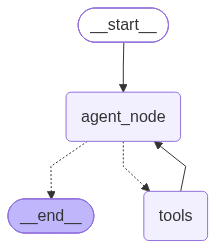

In [21]:
from IPython.display import Image, display
from langgraph.checkpoint.sqlite import SqliteSaver

checkpoint_conn = sqlite3.connect("checkpoints.sqlite", check_same_thread=False)
checkpointer = SqliteSaver(checkpoint_conn)
checkpointer.setup()

graph = StateGraph(State)

graph.add_node("agent_node",agent_node)
graph.add_node("tools",ToolNode(tools))


graph.add_edge(START,"agent_node")
graph.add_conditional_edges("agent_node",tools_condition)
graph.add_edge("tools","agent_node")



graph_builder = graph.compile(checkpointer=checkpointer)


display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [ ]:
from langchain_core.messages import HumanMessage
from langgraph.types import Command


config = {"configurable": {"thread_id": "2"}}

def run_turn(user_text: str):
    result = graph_builder.invoke({"messages": [HumanMessage(content=user_text)]}, config=config)

    while "__interrupt__" in result:
        payload = result["__interrupt__"][0].value
        print("Needs human approval:", payload)
        approved = input("Approve? (y/n): ").strip().lower() == "y"
        result = graph_builder.invoke(Command(resume={"approved": approved}), config=config)

    print(result["messages"][-1].content)
    return result

run_turn("Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.")


Great! I’ve registered you as a new patient (Nour, DOB 2005‑07‑03, phone 201‑017‑989‑362).

Dr. Ahmed Hassan’s open slots on **Monday, 5 October 2026** are:

- 10:00 AM ( slot ID 148 )
- 11:00 AM ( slot ID 149 )
- 12:00 PM ( slot ID 150 )
- 1:00 PM ( slot ID 151 )
- 2:00 PM ( slot ID 152 )
- 3:00 PM ( slot ID 153 )
- 4:00 PM ( slot ID 154 )

Which time would you like to book? Just let me know the preferred hour (e.g., “10 AM”) and I’ll confirm the appointment for you.


{'messages': [HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='99fb68ca-f0b0-42ac-bdee-702ba0a7b2a2'),
  HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='7f0b5d99-759e-41c9-8c1c-2fe2932c69a2'),
  AIMessage(content='Sure! I can help you set that up.\n\nTo book the appointment I’ll need a few details:\n\n1. **Your name** (as it appears on your records)  \n2. **Your phone number** (so I can look up or create your patient profile)  \n3. **The exact date** you’d like—“next Monday” could be\u202f[insert actual date, e.g.,\u202f2024‑10‑07]—please confirm that’s the date you want.  \n\nOnce I have that, I’ll check Dr.\u202fAhmed\u202fHassan’s available slots for that day and get back to you with the options. Let me know the information above, and we’ll go from there!', additional_kwargs={'reasoning_content': "We need t

In [23]:
run_turn("my name is nour and my phone number is 201017989362")

I’ve got your details on file (Nour, phone 201‑017‑989‑362).  

Here are the available times for Dr. Ahmed Hassan on **Monday 5 October 2026**:

- **10:00 AM** (slot ID 148)  
- **11:00 AM** (slot ID 149)  
- **12:00 PM** (slot ID 150)  
- **1:00 PM** (slot ID 151)  
- **2:00 PM** (slot ID 152)  
- **3:00 PM** (slot ID 153)  
- **4:00 PM** (slot ID 154)

Which of these times would you like to book? Just let me know the hour you prefer, and I’ll confirm the appointment for you.


{'messages': [HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='99fb68ca-f0b0-42ac-bdee-702ba0a7b2a2'),
  HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='7f0b5d99-759e-41c9-8c1c-2fe2932c69a2'),
  AIMessage(content='Sure! I can help you set that up.\n\nTo book the appointment I’ll need a few details:\n\n1. **Your name** (as it appears on your records)  \n2. **Your phone number** (so I can look up or create your patient profile)  \n3. **The exact date** you’d like—“next Monday” could be\u202f[insert actual date, e.g.,\u202f2024‑10‑07]—please confirm that’s the date you want.  \n\nOnce I have that, I’ll check Dr.\u202fAhmed\u202fHassan’s available slots for that day and get back to you with the options. Let me know the information above, and we’ll go from there!', additional_kwargs={'reasoning_content': "We need t

In [24]:
run_turn("i want on the secoond of october 2026")

I’ve checked Dr. Ahmed Hassan’s schedule for **Sunday 2 October 2026**, and unfortunately there are no open slots on that day.

Here are a few options you might consider:

1. **Pick a different date** – I can look up his availability for any other day you prefer (e.g., the following Monday, 3 Oct, or any other weekday).  
2. **Choose a different time on a nearby day** – sometimes early‑morning or late‑afternoon slots open up on adjacent days.  
3. **Select another dentist** – if you’re flexible, I can show you the next available slots with one of our other doctors (Dr. Mona Khalil, Dr. Karim Adel, or Dr. Salma Youssef) on 2 Oct or another date.

Please let me know which option works best for you, or suggest a specific alternative date, and I’ll find the available times right away!


{'messages': [HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='99fb68ca-f0b0-42ac-bdee-702ba0a7b2a2'),
  HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='7f0b5d99-759e-41c9-8c1c-2fe2932c69a2'),
  AIMessage(content='Sure! I can help you set that up.\n\nTo book the appointment I’ll need a few details:\n\n1. **Your name** (as it appears on your records)  \n2. **Your phone number** (so I can look up or create your patient profile)  \n3. **The exact date** you’d like—“next Monday” could be\u202f[insert actual date, e.g.,\u202f2024‑10‑07]—please confirm that’s the date you want.  \n\nOnce I have that, I’ll check Dr.\u202fAhmed\u202fHassan’s available slots for that day and get back to you with the options. Let me know the information above, and we’ll go from there!', additional_kwargs={'reasoning_content': "We need t

In [25]:
run_turn("3-7-2005")

I see you’ve confirmed your date of birth as **3 July 2005** (2005‑07‑03), and I’ve already registered you as a patient (Nour, phone 201‑017‑989‑362).

Since Dr. Ahmed Hassan has no openings on **Sunday 2 October 2026**, the next day—**Monday 3 October 2026**—has the following free slots:

| Time | Slot ID |
|------|--------|
| 10:00 AM | 134 |
| 11:00 AM | 135 |
| 12:00 PM | 136 |
| 1:00 PM  | 137 |
| 2:00 PM  | 138 |
| 3:00 PM  | 139 |
| 4:00 PM  | 140 |

Would you like to book one of these times? Just let me know the hour you prefer (e.g., “11 AM”) and I’ll confirm the appointment for you.


{'messages': [HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='99fb68ca-f0b0-42ac-bdee-702ba0a7b2a2'),
  HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='7f0b5d99-759e-41c9-8c1c-2fe2932c69a2'),
  AIMessage(content='Sure! I can help you set that up.\n\nTo book the appointment I’ll need a few details:\n\n1. **Your name** (as it appears on your records)  \n2. **Your phone number** (so I can look up or create your patient profile)  \n3. **The exact date** you’d like—“next Monday” could be\u202f[insert actual date, e.g.,\u202f2024‑10‑07]—please confirm that’s the date you want.  \n\nOnce I have that, I’ll check Dr.\u202fAhmed\u202fHassan’s available slots for that day and get back to you with the options. Let me know the information above, and we’ll go from there!', additional_kwargs={'reasoning_content': "We need t

In [26]:
run_turn("yes")

Great! I’m ready to lock in your appointment, but I need to know which of the available times on **Monday 3 October 2026** works best for you.

The open slots with Dr. Ahmed Hassan are:

- 10:00 AM (slot ID 134)  
- 11:00 AM (slot ID 135)  
- 12:00 PM (slot ID 136)  
- 1:00 PM (slot ID 137)  
- 2:00 PM (slot ID 138)  
- 3:00 PM (slot ID 139)  
- 4:00 PM (slot ID 140)

Please let me know the exact time you’d like, and I’ll book the appointment for you right away.


{'messages': [HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='99fb68ca-f0b0-42ac-bdee-702ba0a7b2a2'),
  HumanMessage(content="Hi, I'd like to book a checkup with Dr. Ahmed Hassan next Monday.", additional_kwargs={}, response_metadata={}, id='7f0b5d99-759e-41c9-8c1c-2fe2932c69a2'),
  AIMessage(content='Sure! I can help you set that up.\n\nTo book the appointment I’ll need a few details:\n\n1. **Your name** (as it appears on your records)  \n2. **Your phone number** (so I can look up or create your patient profile)  \n3. **The exact date** you’d like—“next Monday” could be\u202f[insert actual date, e.g.,\u202f2024‑10‑07]—please confirm that’s the date you want.  \n\nOnce I have that, I’ll check Dr.\u202fAhmed\u202fHassan’s available slots for that day and get back to you with the options. Let me know the information above, and we’ll go from there!', additional_kwargs={'reasoning_content': "We need t

In [27]:
run_turn("3rd of july")

RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_REDACTED` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 3853, Requested 4190. Please try again in 322.499999ms. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}